In [1]:
!pip install torch torchvision matplotlib pillow numpy --break-system-packages -q

In [11]:
import torch
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

In [3]:
class ForwardDiffusion:
    def __init__(self, timesteps=1000, beta_start=0.0001, beta_end=0.02):
        self.timesteps = timesteps
        self.betas = torch.linspace(beta_start, beta_end, timesteps)
        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=0)
        self.sqrt_alphas_cumprod = torch.sqrt(self.alphas_cumprod)
        self.sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - self.alphas_cumprod)

    def forward_diffusion_sample(self, x_0, t):
        noise = torch.randn_like(x_0)
        sqrt_alpha_bar_t = self.sqrt_alphas_cumprod[t].view(-1, 1, 1, 1)
        sqrt_one_minus_alpha_bar_t = self.sqrt_one_minus_alphas_cumprod[t].view(-1, 1, 1, 1)
        x_t = sqrt_alpha_bar_t * x_0 + sqrt_one_minus_alpha_bar_t * noise
        return x_t, noise

In [13]:
def load_images(image_paths, image_size=128):
    transform = transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
    ])

    images = []
    for img_path in image_paths:
        img = Image.open(img_path).convert('RGB')
        img_tensor = transform(img)
        images.append(img_tensor)

    return torch.stack(images)

image_paths = [
    'image1.jpg',
    'image2.jpg',
    'image3.jpg',
    'image4.jpg',
    'image5.jpg'
]

images = load_images(image_paths, image_size=128)
print(f"Loaded {images.shape[0]} images, shape: {images.shape}")

Loaded 5 images, shape: torch.Size([5, 3, 128, 128])


In [14]:
diffusion = ForwardDiffusion(timesteps=1000, beta_start=0.0001, beta_end=0.02)
print(f"Timesteps: {diffusion.timesteps}")
print(f"Beta range: [{diffusion.betas[0]:.6f}, {diffusion.betas[-1]:.6f}]")

Timesteps: 1000
Beta range: [0.000100, 0.020000]


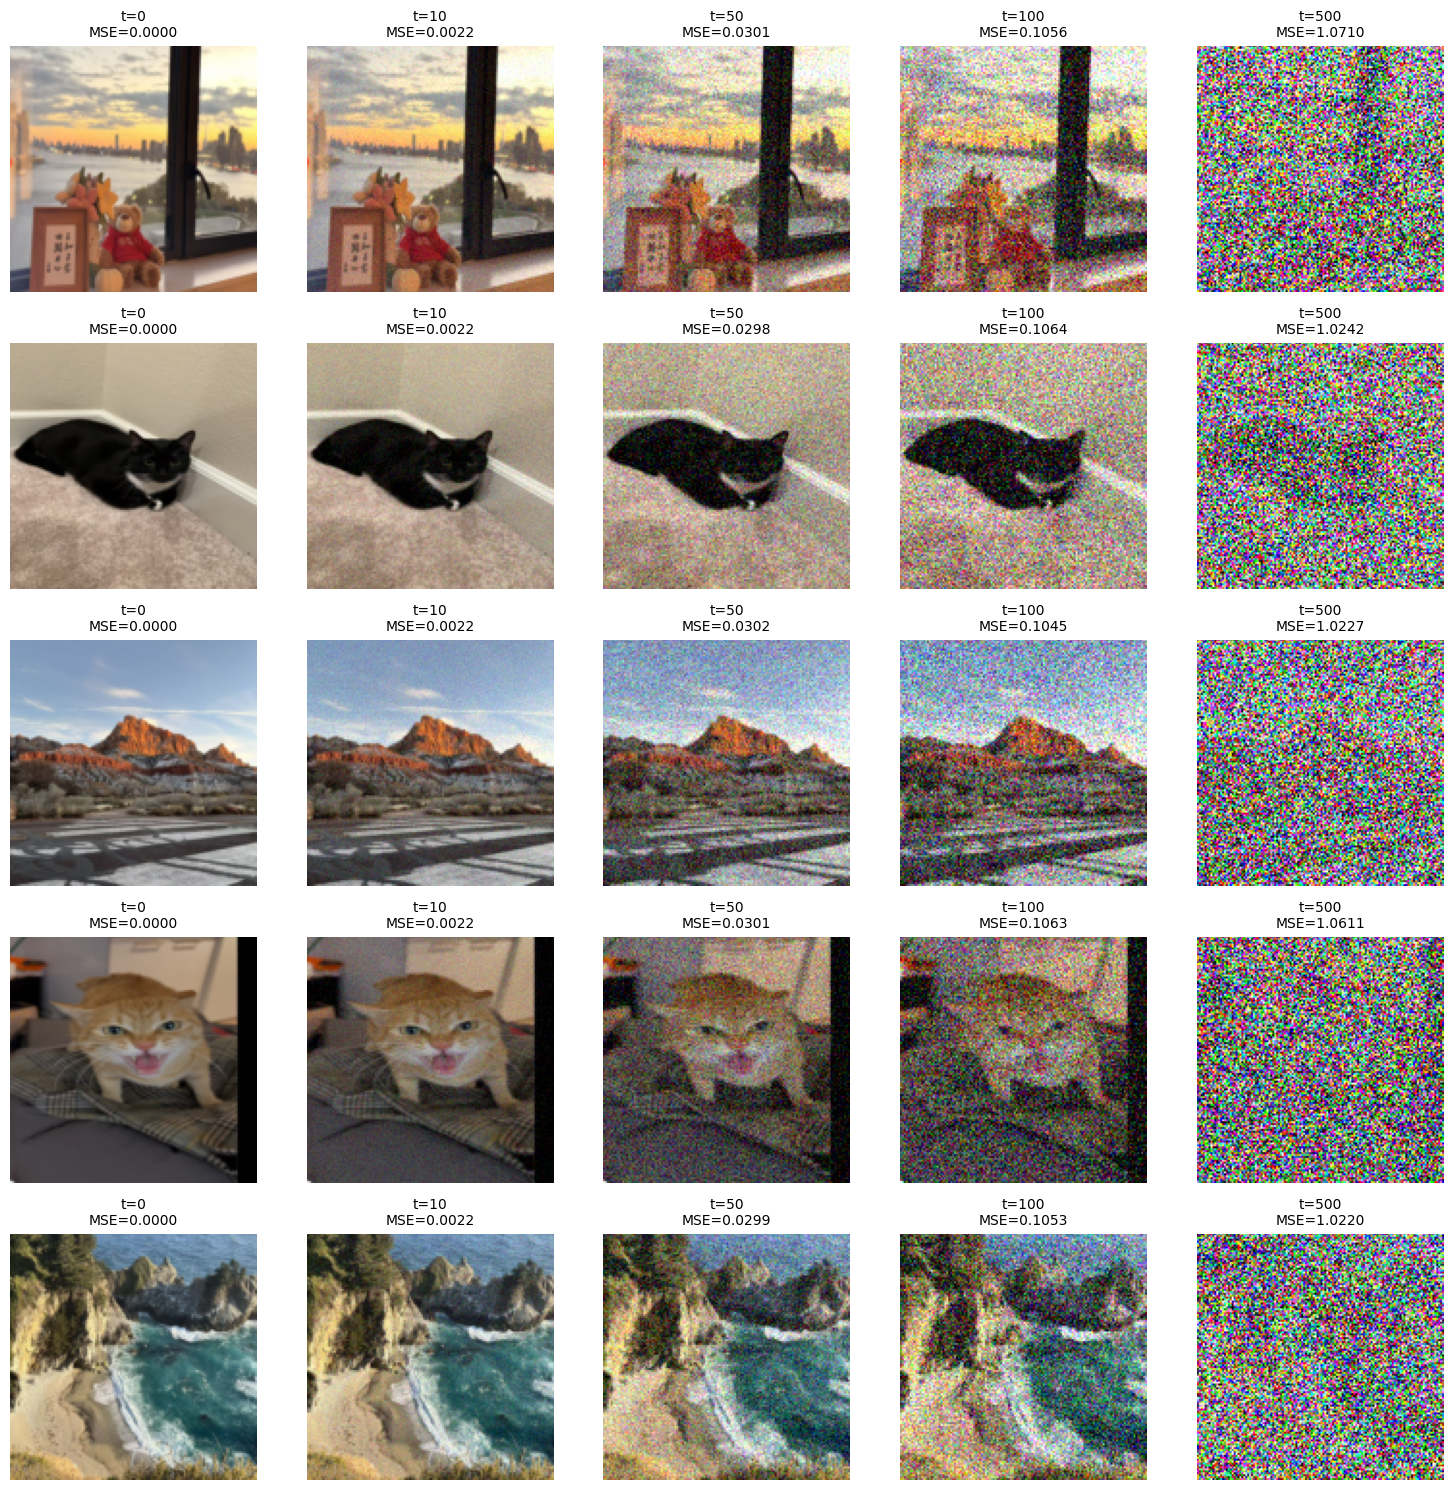


Average MSE at each timestep:
----------------------------------------
t =    0: MSE = 0.000000
t =   10: MSE = 0.002198
t =   50: MSE = 0.030016
t =  100: MSE = 0.105633
t =  500: MSE = 1.040223


In [15]:
def calculate_mse(original, noisy):
    return torch.mean((original - noisy) ** 2).item()

timesteps_to_show = [0, 10, 50, 100, 500]
num_images = images.shape[0]
num_timesteps = len(timesteps_to_show)

fig, axes = plt.subplots(num_images, num_timesteps, figsize=(3*num_timesteps, 3*num_images))
mse_values = {t: [] for t in timesteps_to_show}

for i in range(num_images):
    x_0 = images[i:i+1]

    for j, t in enumerate(timesteps_to_show):
        if t == 0:
            x_t = x_0
        else:
            t_tensor = torch.tensor([t])
            x_t, noise = diffusion.forward_diffusion_sample(x_0, t_tensor)

        mse = calculate_mse(x_0, x_t)
        mse_values[t].append(mse)

        img_to_show = (x_t[0].permute(1, 2, 0).cpu().numpy() + 1) / 2
        img_to_show = np.clip(img_to_show, 0, 1)

        if num_images > 1:
            ax = axes[i, j]
        else:
            ax = axes[j]
        ax.imshow(img_to_show)
        ax.axis('off')
        ax.set_title(f't={t}\nMSE={mse:.4f}', fontsize=10)

plt.tight_layout()
plt.savefig('diffusion_process.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nAverage MSE at each timestep:")
print("-" * 40)
for t in timesteps_to_show:
    avg_mse = np.mean(mse_values[t])
    print(f"t = {t:4d}: MSE = {avg_mse:.6f}")

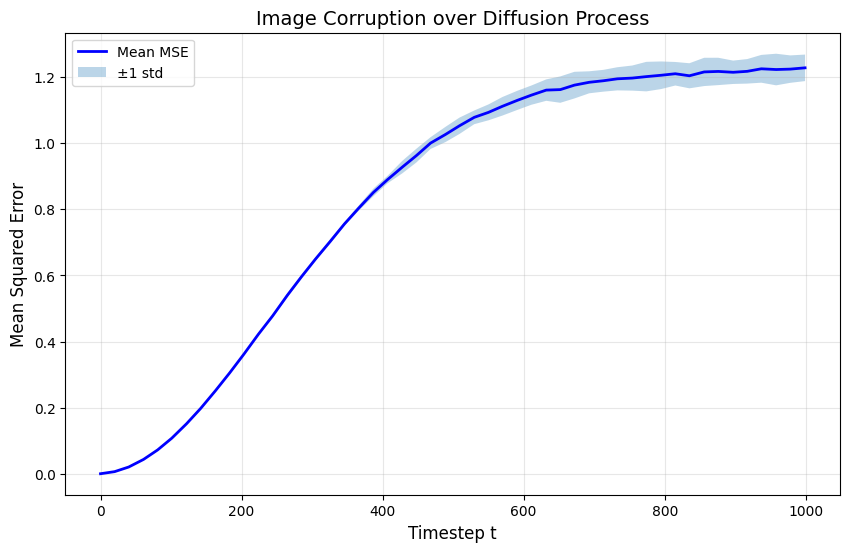

Complete!


In [16]:
timesteps = np.linspace(0, diffusion.timesteps-1, 50, dtype=int)
mse_means = []
mse_stds = []

for t in timesteps:
    mses = []
    for i in range(images.shape[0]):
        x_0 = images[i:i+1]
        if t == 0:
            x_t = x_0
        else:
            t_tensor = torch.tensor([t])
            x_t, _ = diffusion.forward_diffusion_sample(x_0, t_tensor)
        mses.append(calculate_mse(x_0, x_t))

    mse_means.append(np.mean(mses))
    mse_stds.append(np.std(mses))

plt.figure(figsize=(10, 6))
mse_means = np.array(mse_means)
mse_stds = np.array(mse_stds)

plt.plot(timesteps, mse_means, 'b-', linewidth=2, label='Mean MSE')
plt.fill_between(timesteps, mse_means - mse_stds, mse_means + mse_stds,
                 alpha=0.3, label='±1 std')

plt.xlabel('Timestep t', fontsize=12)
plt.ylabel('Mean Squared Error', fontsize=12)
plt.title('Image Corruption over Diffusion Process', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend()
plt.savefig('mse_curve.png', dpi=150, bbox_inches='tight')
plt.show()

print("Complete!")

Model loaded on cuda
Fixed noise created: torch.Size([4, 3, 32, 32])

Sampling with 100 steps...


DDIM 100 steps: 100%|██████████| 100/100 [00:02<00:00, 46.00it/s]


Generated 4 images

Sampling with 50 steps...


DDIM 50 steps: 100%|██████████| 50/50 [00:00<00:00, 51.86it/s]


Generated 4 images

Sampling with 10 steps...


DDIM 10 steps: 100%|██████████| 10/10 [00:00<00:00, 49.70it/s]


Generated 4 images


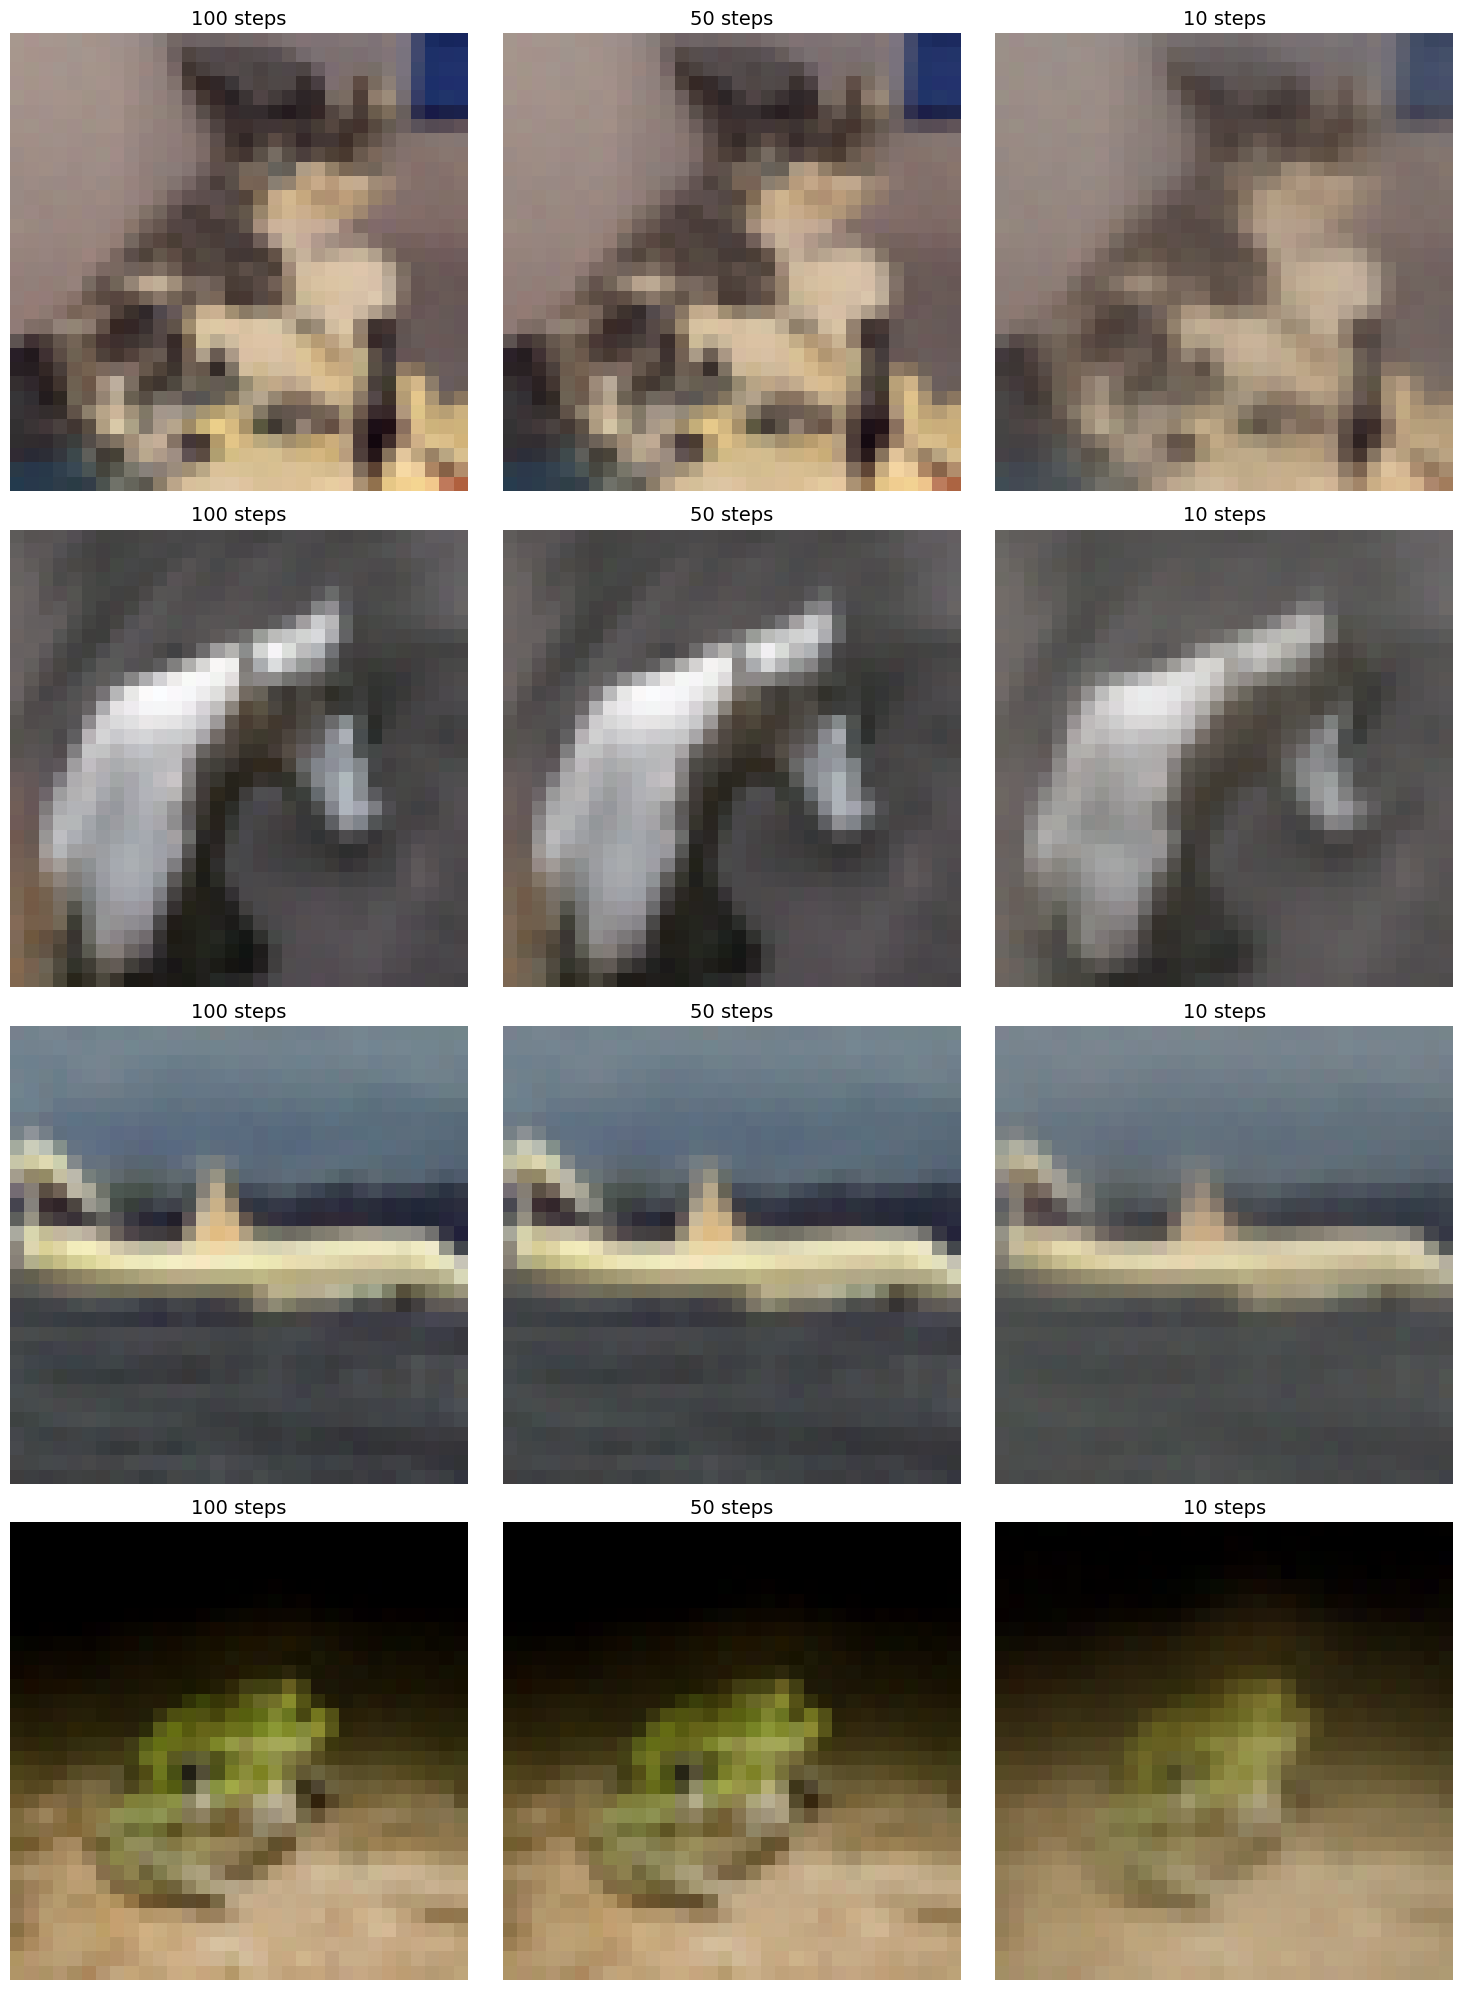


Verifying deterministic property...


DDIM 50 steps: 100%|██████████| 50/50 [00:00<00:00, 52.49it/s]


Max difference: 0.0000000000
Identical: True

Quality metrics:
50 steps vs 100 steps: MSE = 0.000174
10 steps vs 100 steps: MSE = 0.009430


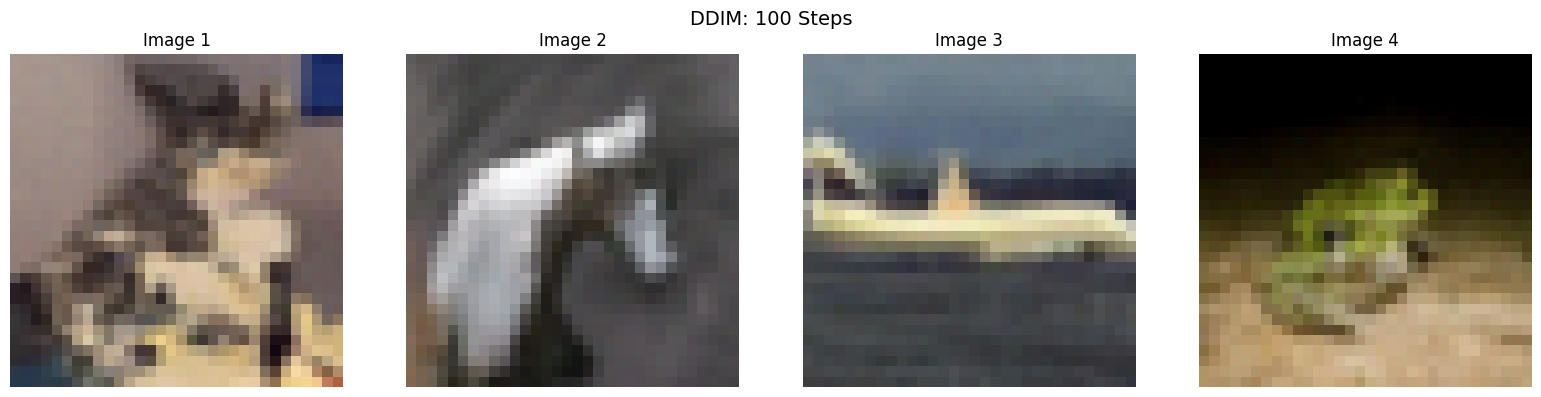

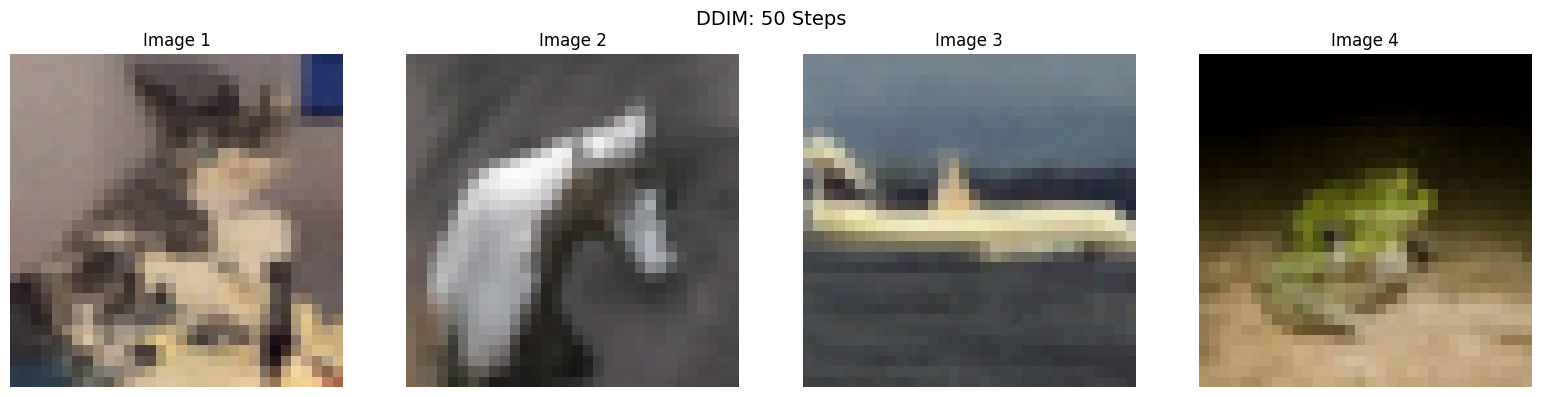

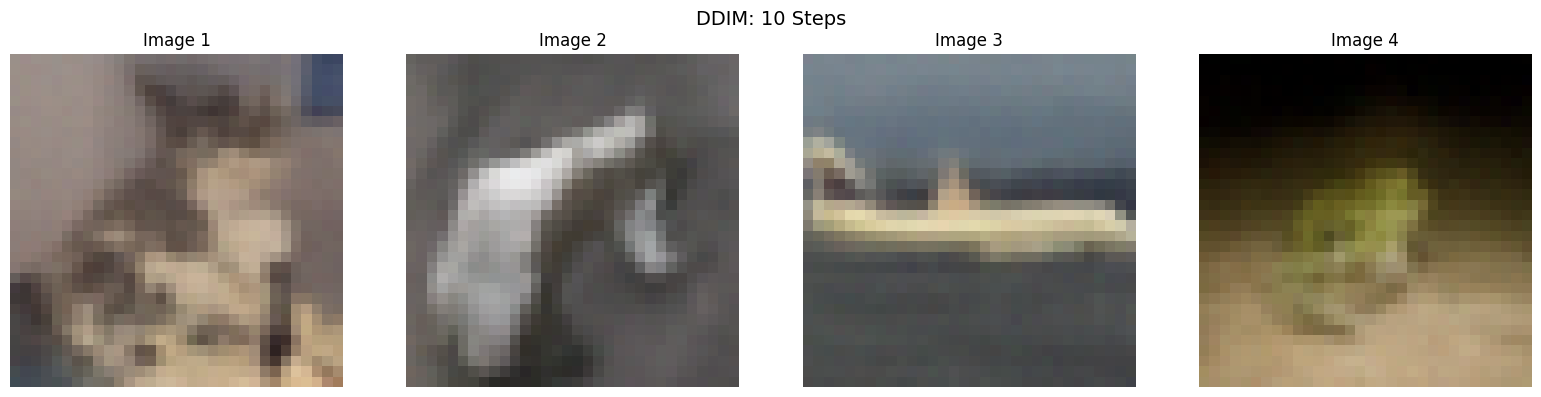

In [3]:

import torch
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from diffusers import DDIMScheduler, UNet2DModel

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = UNet2DModel.from_pretrained("google/ddpm-cifar10-32").to(device)

scheduler = DDIMScheduler(
    num_train_timesteps=1000,
    beta_start=0.0001,
    beta_end=0.02,
    beta_schedule="linear",
    clip_sample=False,
    set_alpha_to_one=False,
    prediction_type="epsilon"
)

print(f"Model loaded on {device}")

torch.manual_seed(42)
batch_size = 4
image_size = 32
channels = 3
fixed_noise = torch.randn(batch_size, channels, image_size, image_size, device=device)

print(f"Fixed noise created: {fixed_noise.shape}")

@torch.no_grad()
def ddim_sample(model, scheduler, num_inference_steps, x_T, device='cpu'):
    scheduler.set_timesteps(num_inference_steps)
    x_t = x_T.clone()

    for t in tqdm(scheduler.timesteps, desc=f'DDIM {num_inference_steps} steps'):
        model_output = model(x_t, t).sample
        x_t = scheduler.step(model_output, t, x_t, eta=0.0).prev_sample

    return x_t

steps_list = [100, 50, 10]
results = {}

for num_steps in steps_list:
    print(f"\nSampling with {num_steps} steps...")
    samples = ddim_sample(model, scheduler, num_steps, fixed_noise, device)
    results[num_steps] = samples.cpu()
    print(f"Generated {samples.shape[0]} images")

def process_image(tensor):
    img = tensor.cpu().numpy()
    img = (img + 1) / 2
    img = np.clip(img, 0, 1)
    img = np.transpose(img, (1, 2, 0))
    return img

num_samples = 4
num_cols = len(steps_list)

fig, axes = plt.subplots(num_samples, num_cols, figsize=(5*num_cols, 5*num_samples))

for i in range(num_samples):
    for j, num_steps in enumerate(steps_list):
        img_tensor = results[num_steps][i]
        img = process_image(img_tensor)

        ax = axes[i, j]
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f'{num_steps} steps', fontsize=14)

plt.tight_layout()
plt.savefig('ddim_comparison.png', dpi=150)
plt.show()

print("\nVerifying deterministic property...")

sample1 = ddim_sample(model, scheduler, 50, fixed_noise, device).cpu()
sample2 = ddim_sample(model, scheduler, 50, fixed_noise, device).cpu()

max_diff = torch.abs(sample1 - sample2).max().item()
are_identical = torch.allclose(sample1, sample2, atol=1e-5)

print(f"Max difference: {max_diff:.10f}")
print(f"Identical: {are_identical}")

def compute_mse(img1, img2):
    return torch.mean((img1 - img2) ** 2).item()

baseline = results[100]

print("\nQuality metrics:")
for num_steps in [50, 10]:
    current = results[num_steps]
    mse = compute_mse(baseline, current)
    print(f"{num_steps} steps vs 100 steps: MSE = {mse:.6f}")

for num_steps in steps_list:
    fig, axes = plt.subplots(1, num_samples, figsize=(4*num_samples, 4))

    for i in range(num_samples):
        img_tensor = results[num_steps][i]
        img = process_image(img_tensor)

        axes[i].imshow(img)
        axes[i].axis('off')
        axes[i].set_title(f'Image {i+1}', fontsize=12)

    plt.suptitle(f'DDIM: {num_steps} Steps', fontsize=14)
    plt.tight_layout()
    plt.savefig(f'ddim_{num_steps}_steps.png', dpi=150)
    plt.show()


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

  0%|          | 0/37 [00:00<?, ?it/s]

Generating: a sunny day at the beach


  0%|          | 0/50 [00:00<?, ?it/s]

Editing to: a rainy day at the beach


  0%|          | 0/37 [00:00<?, ?it/s]

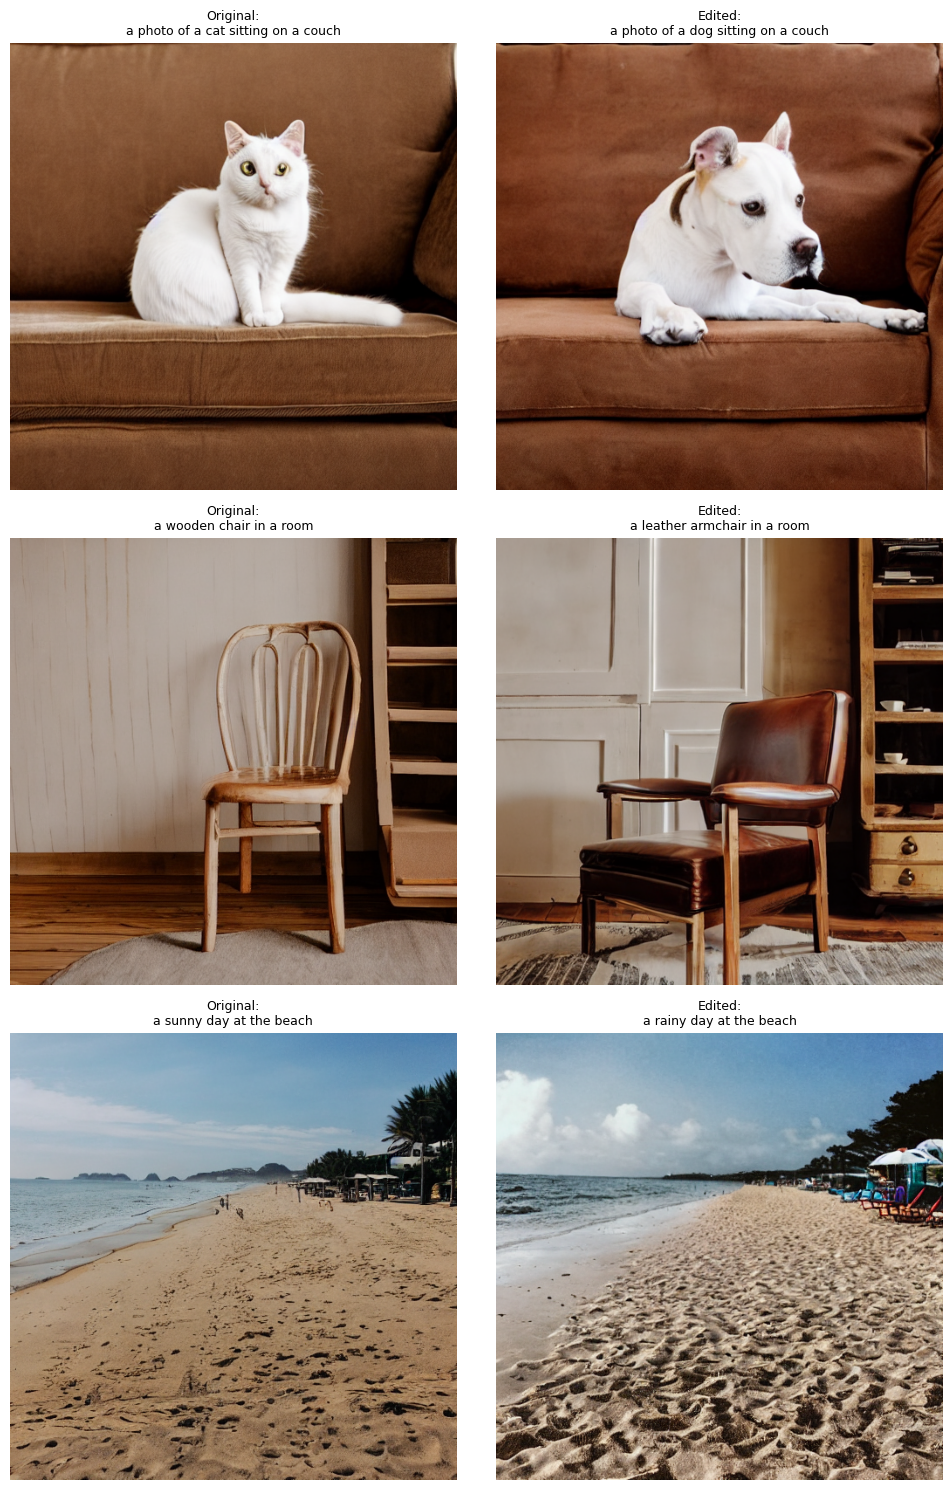

In [1]:
import torch
from diffusers import StableDiffusionPipeline, StableDiffusionImg2ImgPipeline
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

txt2img = StableDiffusionPipeline.from_pretrained("runwayml/stable-diffusion-v1-5", torch_dtype=torch.float16 if device=="cuda" else torch.float32).to(device)

img2img = StableDiffusionImg2ImgPipeline.from_pretrained("runwayml/stable-diffusion-v1-5", torch_dtype=torch.float16 if device=="cuda" else torch.float32).to(device)

print(f"Models loaded on {device}")

edit_examples = [
    ("a photo of a cat sitting on a couch", "a photo of a dog sitting on a couch"),
    ("a wooden chair in a room", "a leather armchair in a room"),
    ("a sunny day at the beach", "a rainy day at the beach")
]

results = []

for original_prompt, edited_prompt in edit_examples:
    print(f"Generating: {original_prompt}")

    gen1 = torch.Generator(device=device).manual_seed(42)
    original_image = txt2img(original_prompt, num_inference_steps=50, generator=gen1).images[0]

    print(f"Editing to: {edited_prompt}")

    edited_image = img2img(prompt=edited_prompt, image=original_image, strength=0.75, num_inference_steps=50).images[0]

    results.append((original_image, edited_image, original_prompt, edited_prompt))

fig, axes = plt.subplots(len(results), 2, figsize=(10, 5*len(results)))

for idx, (orig_img, edit_img, orig_prompt, edit_prompt) in enumerate(results):
    axes[idx, 0].imshow(orig_img)
    axes[idx, 0].axis('off')
    axes[idx, 0].set_title(f"Original:\n{orig_prompt}", fontsize=9)

    axes[idx, 1].imshow(edit_img)
    axes[idx, 1].axis('off')
    axes[idx, 1].set_title(f"Edited:\n{edit_prompt}", fontsize=9)

plt.tight_layout()
plt.savefig('results.png', dpi=150)
plt.show()